# Mini Quantization · 从张量到模型

在普通 CPU 电脑上，用自己实现的 PyTorch helper 理解量化映射、重建误差和权重存储。

本 Notebook 由用户提供的 Python 导出脚本恢复并按学习主题归整。`helper.py` 保留原始实现；整理前脚本位于 `original/mini_quantization_export.py`。

**主线：** 非对称量化 → 对称量化 → 逐通道 / 分组量化 → 量化线性层 → 模型层替换。

CodeGen、DETR 默认跳过；OPT 和远端上传章节按需手动运行。详细运行方式与待修复边界见 [项目说明](README.md)。文件中没有预填输出，未把未运行的模型结果标为已验证。


## 0. 环境与实验开关

先在本目录安装 `requirements.txt`。Windows 保留原脚本中先导入 `msvc_runtime` 的顺序；其他系统跳过。固定随机种子后，在同一次实验中保留输入，再改变一个参数做比较。


In [1]:
import sys
if sys.platform == "win32":
    import msvc_runtime  # 保留原 Windows 环境的导入顺序
import torch
import importlib
import helper
from torch import nn
importlib.reload(helper)
import torch.nn.functional as F
from helper import (
    linear_q_with_scale_and_zero_point,
    linear_dequantization,
    get_q_scale_and_zero_point,
    linear_quantizaton,
    get_q_scale_symmetric,
    linear_q_symmetric,
    linear_q_symmetric_per_channel,
    linear_q_symmetric_per_group,
    linear_dequantization_per_group,
    plot_quantization_errors,
    quantized_linear_W8A32_without_bias,
    w8_a16_forward,
    W8A16LinearLayer,
    replace_linear_with_target,
    replace_linear_with_target_and_quantize,
    DummyModel,
    plot_detection_results,
    pack_weights,
    unpack_weights,
)

from pathlib import Path
from IPython.display import display
torch.manual_seed(42)
print("PyTorch:", torch.__version__, "| 本实验使用 CPU")


PyTorch: 2.15.0+cu132 | 本实验使用 CPU


In [76]:
# 基础张量实验无需下载模型。按需开启可选实验。
RUN_CODEGEN = False
RUN_DETR = False

IMAGE_PATH = "dinner.jpg"


## 1. 非对称线性量化（INT8）

- `scale = (r_max - r_min) / (q_max - q_min)`
- `zero_point = clamp(round(q_min - r_min / scale), q_min, q_max)`
- `q = clamp(round(x / scale + zero_point), q_min, q_max)`
- `x_hat = scale * (q - zero_point)`

这里沿用原 helper 的“先加零点，再取整”顺序。先观察随机输入，再在后续验收中补充全正、全负与常数输入。


In [3]:
r_tensor = torch.randn((4, 4))
r_tensor


tensor([[ 1.9269,  1.4873,  0.9007, -2.1055],
        [ 0.6784, -1.2345, -0.0431, -1.6047],
        [-0.7521,  1.6487, -0.3925, -1.4036],
        [-0.7279, -0.5594, -0.7688,  0.7624]])

In [4]:
quantized_tensor, scale, zero_point = linear_quantizaton(r_tensor)
print(f"scale:       {scale}")
print(f"zero_point:  {zero_point}")
print(f"quantized:\n{quantized_tensor}")


scale:       0.015813475496628704
zero_point:  5
quantized:
tensor([[ 127,   99,   62, -128],
        [  48,  -73,    2,  -96],
        [ -43,  109,  -20,  -84],
        [ -41,  -30,  -44,   53]], dtype=torch.int8)


In [5]:
dequantized_tensor = linear_dequantization(quantized_tensor, scale, zero_point)
dequantized_tensor


tensor([[ 1.9292,  1.4865,  0.9014, -2.1032],
        [ 0.6800, -1.2335, -0.0474, -1.5972],
        [-0.7590,  1.6446, -0.3953, -1.4074],
        [-0.7274, -0.5535, -0.7749,  0.7590]])

In [6]:
(r_tensor - dequantized_tensor).square().mean()


tensor(1.6366e-05)

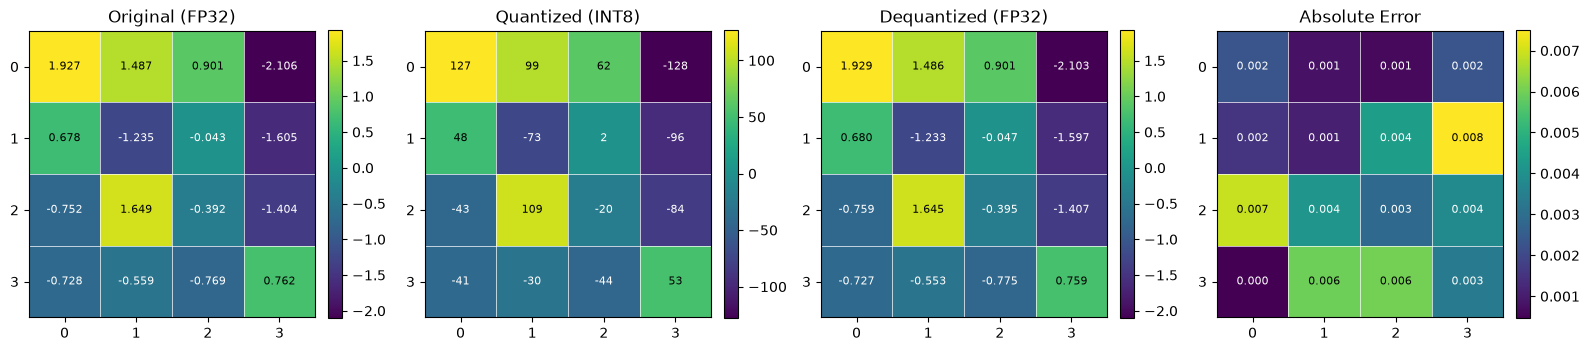

Max Absolute Error : 0.007506
Mean Absolute Error: 0.003386
MSE                : 0.000016


In [7]:
plot_quantization_errors(r_tensor, quantized_tensor, dequantized_tensor)


## 2. 对称线性量化（INT8）

`scale = max(abs(x)) / q_max`，`zero_point = 0`。原 helper 使用 dtype 的完整整数范围裁剪。

先观察随机数据，再观察一个大动态范围的小矩阵。比较 MSE 时也要看输入尺度，不能把两个不同输入的误差大小直接当成算法优劣。


In [8]:
test_tensor = torch.randn((4, 4))
print(f"symmetric scale: {get_q_scale_symmetric(test_tensor)}")


symmetric scale: 0.01323323268590011


In [9]:
quantizated_tensor, scale = linear_q_symmetric(test_tensor)
quantizated_tensor


tensor([[124, -12, -38,  33],
        [-57,  81,  61, 127],
        [ 97,  98,  46, 101],
        [-18,   3, -19,  65]], dtype=torch.int8)

In [10]:
dequantized_tensor = linear_dequantization(quantizated_tensor, scale, zero_point=0)
dequantized_tensor


tensor([[ 1.6409, -0.1588, -0.5029,  0.4367],
        [-0.7543,  1.0719,  0.8072,  1.6806],
        [ 1.2836,  1.2969,  0.6087,  1.3366],
        [-0.2382,  0.0397, -0.2514,  0.8602]])

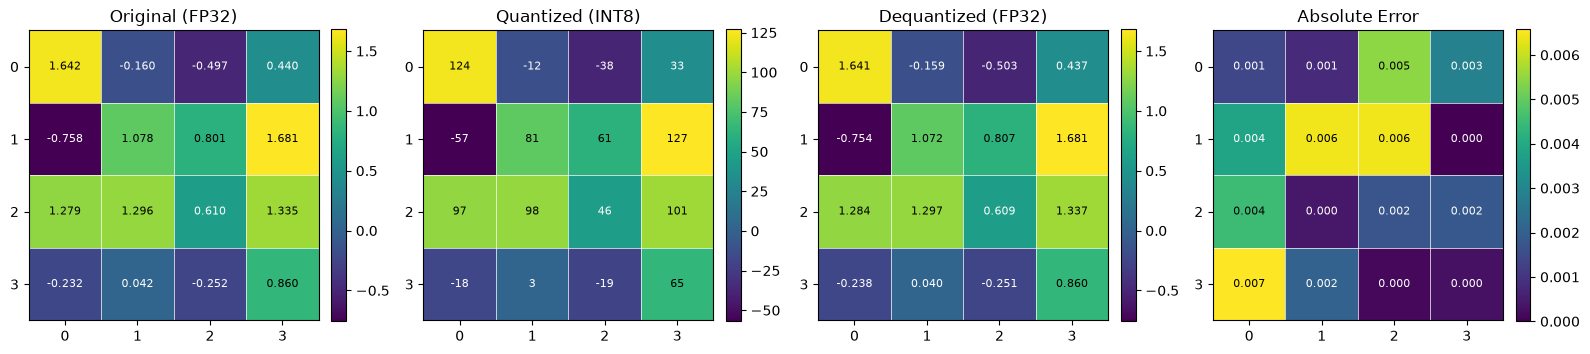

Max Absolute Error : 0.006574
Mean Absolute Error: 0.002801
MSE                : 0.000013


In [11]:
plot_quantization_errors(test_tensor, quantizated_tensor, dequantized_tensor)


In [12]:
test_tensor = torch.tensor(
    [[191.6, -13.5, 728.6],
    [92.14, 295.5, -184],
    [0, 684.6, 245.5]]
)


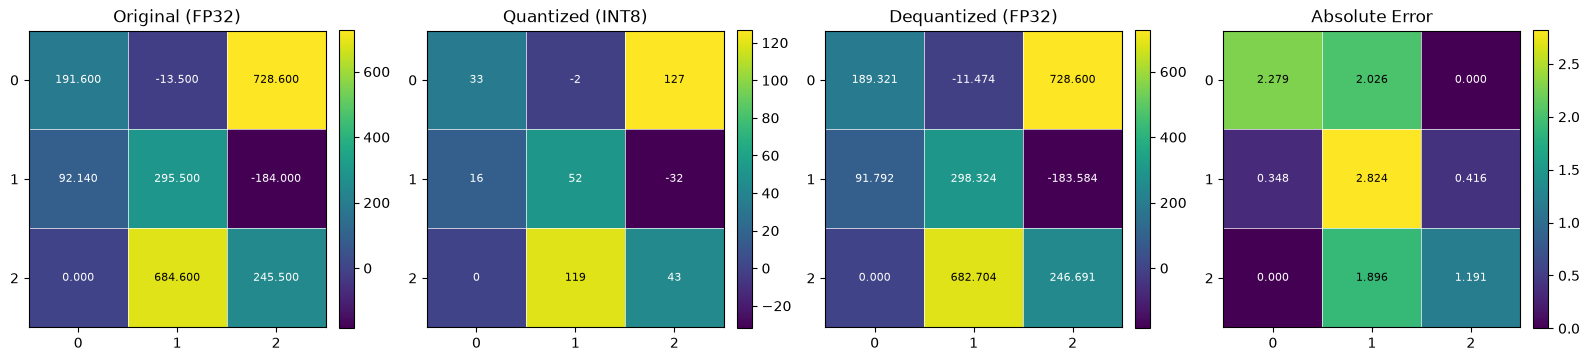

Max Absolute Error : 2.824402
Mean Absolute Error: 1.220017
MSE                : 2.509191


In [13]:
quantizated_tensor, scale = linear_q_symmetric(test_tensor)
dequantized_tensor = linear_dequantization(quantizated_tensor, scale, zero_point=0)
plot_quantization_errors(test_tensor, quantizated_tensor, dequantized_tensor)


## 3. 逐通道量化：行与列分别意味着什么？

固定同一个矩阵，对比全局 scale、每行 scale（`dim=0`）与每列 scale（`dim=1`）。

观察：scale 的形状怎样广播回原张量？误差改变的同时多存储了多少个 scale？结论以这组输入的实际结果为准。


In [14]:
# 用大动态范围数据, 对比 per-tensor vs per-channel
test_tensor = torch.tensor(
    [[191.6, -13.5, 728.6],
    [92.14, 295.5, -184],
    [0, 684.6, 245.5]]
)

# per-tensor (全局一个 scale)
q_per_tensor, s_tensor = linear_q_symmetric(test_tensor)
dq_per_tensor = linear_dequantization(q_per_tensor, s_tensor, zero_point=0)
mse_per_tensor = (test_tensor - dq_per_tensor).square().mean()
print(f"Per-Tensor MSE:  {mse_per_tensor.item():.4f}")

# per-channel (每行独立 scale)
q_per_channel, s_channel = linear_q_symmetric_per_channel(test_tensor, dim=0)
dq_per_channel = linear_dequantization(q_per_channel, s_channel, zero_point=0)
mse_per_channel = (test_tensor - dq_per_channel).square().mean()
print(f"Per-Channel dim=0 MSE: {mse_per_channel.item():.4f}")

# per-channel (每列独立scale)
q_per_channel, s_channel = linear_q_symmetric_per_channel(test_tensor, dim=1)
dq_per_channel = linear_dequantization(q_per_channel, s_channel, zero_point=0)
mse_per_channel = (test_tensor - dq_per_channel).square().mean()
print(f"Per-Channel dim=1 MSE: {mse_per_channel.item():.4f}")


Per-Tensor MSE:  2.5092
Per-Channel dim=0 MSE: 1.8084
Per-Channel dim=1 MSE: 1.0781


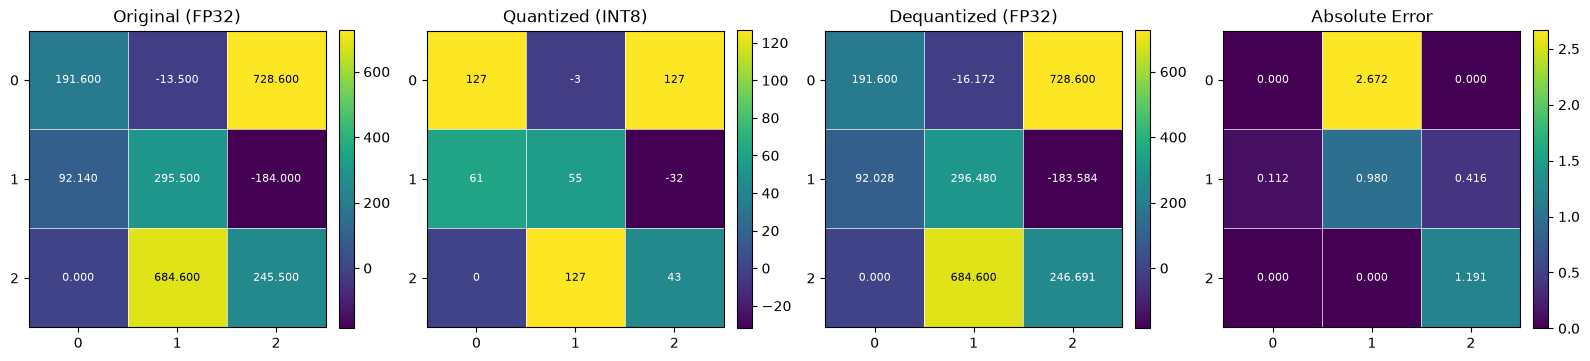

Max Absolute Error : 2.671654
Mean Absolute Error: 0.596745
MSE                : 1.078149


In [15]:
plot_quantization_errors(test_tensor, q_per_channel, dq_per_channel)


## 4. 分组量化（Per-group）

原 helper 将二维张量按连续的 `group_size` 个元素拆分，每组独立计算 scale，再恢复原形状。

先运行 `group_size=6`，之后用同一个输入比较 1、2、3、6。记录误差、scale 个数，并说明哪些输入形状符合该实现的限制。


In [16]:
test_tensor = torch.rand((6,6))


In [17]:
group_size = 6


In [18]:
quantized_tensor, scale = linear_q_symmetric_per_group(test_tensor, group_size)


In [19]:
dequantized_tensor = linear_dequantization_per_group(quantized_tensor, scale, group_size)


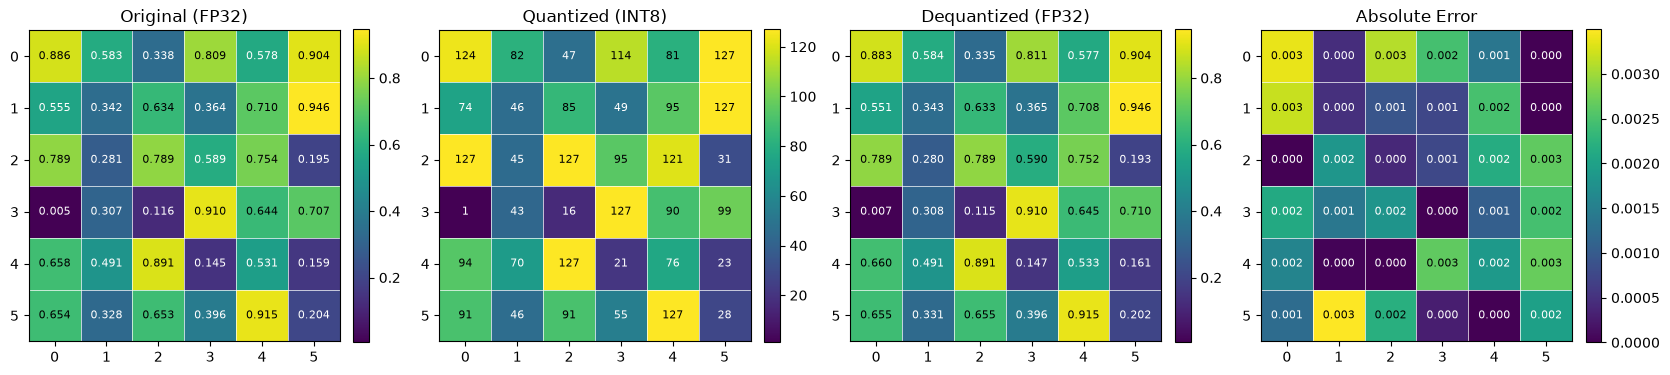

Max Absolute Error : 0.003498
Mean Absolute Error: 0.001481
MSE                : 0.000003


In [20]:
plot_quantization_errors(test_tensor, quantized_tensor, dequantized_tensor)


## 4.1 低比特权重打包与解包

量化后每个 2-bit 码值只需要 2 位，但单独用 `torch.uint8` 保存仍占 1 字节。本例将每 4 个码值放入 1 个字节，再解包恢复原始码值。

- `pack_weights` 按低位优先排列：较早的码值存入字节的低位。
- 支持 1、2、4、8 bit；输入为一维 `torch.uint8`，每个值需在 `[0, 2**bits - 1]`，且长度需填满字节。
- 打包是无损的存储布局转换，不是再次量化；解包后仍是整数码值，不是反量化浮点权重。
- 下面只计算码值本身的字节数，没有计入 scale、zero-point、形状等元数据，也不用于推断推理加速。


In [ ]:
# 8 个已经量化到 [0, 3] 的 2-bit 码值，先以 uint8 保存。
bits = 2
weights = torch.tensor([0, 1, 2, 3, 3, 2, 1, 0], dtype=torch.uint8)

packed_weights = pack_weights(weights, bits)
unpacked_weights = unpack_weights(packed_weights, bits)

print("原始码值:", weights.tolist())
print("打包字节:", packed_weights.tolist())
print("二进制:", [f"{value:08b}" for value in packed_weights.tolist()])
print("解包码值:", unpacked_weights.tolist())

assert packed_weights.tolist() == [228, 27]  # 验证每个字节内的位排列
assert torch.equal(weights, unpacked_weights)  # 验证无损恢复

before_bytes = weights.numel() * weights.element_size()
after_bytes = packed_weights.numel() * packed_weights.element_size()
print(f"码值存储: {before_bytes} B -> {after_bytes} B，缩小 {before_bytes / after_bytes:.0f} 倍")
print("无损恢复:", torch.equal(weights, unpacked_weights))


## 5. W8A32 线性层：权重量化后输出差多少？

激活为 FP32，权重先做 INT8 对称量化，再反量化调用浮点线性运算。对照同一个输入下的原始 FP32 输出。

本示例 `z_w=0`。helper 的该函数目前没有正确处理非零 zero-point，已列为待修复项。


In [21]:
input = torch.tensor([1, 2, 3], dtype = torch.float32)


In [22]:
weight = torch.tensor([[-2, -1.13, 0.42],
                      [-1.51, 0.25, 1.62],
                      [0.12, 1.35, 2.15]])


In [23]:
q_w, s_w = linear_q_symmetric(weight)


In [24]:
q_w


tensor([[-118,  -67,   25],
        [ -89,   15,   96],
        [   7,   80,  127]], dtype=torch.int8)

In [25]:
s_w


0.016929134609192376

In [26]:
output = quantized_linear_W8A32_without_bias(input, q_w, s_w, 0)


In [27]:
print(f"This is the W8A32 output: {output}")


This is the W8A32 output: tensor([-2.9965,  3.8768,  9.2772])


In [28]:
fp32_output =  torch.nn.functional.linear(input, weight)


In [29]:
print(f"This is the output if we don't quantize: {fp32_output}")


This is the output if we don't quantize: tensor([-3.0000,  3.8500,  9.2700])


## 6. 量化线性层：存储 dtype 与计算 dtype

类名 `W8A16LinearLayer` 沿用原实现，但实际输入 dtype 决定浮点计算类型。本例权重为 BF16，不能把它写成 FP16 激活的实验结果。

整理时把模块的形状声明改为 `in_features=8, out_features=4`，与原脚本的 `(4, 8)` 权重一致。这里先观察权重重建误差，尚未验证真实模型的速度收益。


In [30]:
module = W8A16LinearLayer(in_features=8, out_features=4, dtype=torch.bfloat16)


In [31]:
random_matrix = torch.randn((4, 8), dtype = torch.bfloat16)


In [32]:
random_matrix


tensor([[ 0.7266,  0.0913, -0.3887,  0.5273,  1.0312, -0.7031,  1.0156, -0.3301],
        [ 1.0938,  0.3398,  0.7188,  0.4121, -0.5742,  0.5078, -0.4746, -0.4922],
        [-0.1357,  1.6328,  0.6562,  0.5742, -0.3613, -0.0605,  0.0732,  0.8203],
        [-0.3750,  1.0312, -0.6875,  0.6367,  0.2178, -0.0466, -1.4297, -0.5664]],
       dtype=torch.bfloat16)

In [33]:
module.quantize(random_matrix)


In [34]:
module.int8_weights


tensor([[  90,   11,  -48,   65,  127,  -86,  125,  -41],
        [ 127,   40,   84,   48,  -66,   59,  -55,  -57],
        [ -11,  127,   51,   44,  -28,   -5,    6,   64],
        [ -34,   92,  -61,   57,   19,   -4, -128,  -50]], dtype=torch.int8)

In [35]:
module.scales.shape


torch.Size([4])

In [36]:
module.int8_weights.shape


torch.Size([4, 8])

In [37]:
dequantized_weights = module.int8_weights*module.scales.unsqueeze(1)


In [38]:
dequantized_weights


tensor([[ 0.7305,  0.0894, -0.3906,  0.5273,  1.0312, -0.6992,  1.0156, -0.3320],
        [ 1.0938,  0.3438,  0.7227,  0.4141, -0.5664,  0.5078, -0.4727, -0.4902],
        [-0.1416,  1.6328,  0.6562,  0.5664, -0.3613, -0.0645,  0.0771,  0.8242],
        [-0.3828,  1.0312, -0.6836,  0.6406,  0.2129, -0.0449, -1.4375, -0.5625]],
       dtype=torch.bfloat16)

In [39]:
(random_matrix - dequantized_weights).square().mean()


tensor(1.5020e-05, dtype=torch.bfloat16)

## 7. 递归替换模型中的 Linear

先看“只替换结构”，再看“替换并量化原权重”。`DummyModel` 中保留 `lm_head`，检查打印出的层结构。

原实现按叶子模块名匹配排除项，而不是完整层路径。真实模型使用 `"0"`、`"1"` 等排除项时，应先确认它们实际匹配了哪些位置。


In [40]:
model_1 = DummyModel()
model_2 = DummyModel()


In [41]:
replace_linear_with_target(model_1, W8A16LinearLayer, ["lm_head"])


In [42]:
print(model_1)


DummyModel(
  (emb): Embedding(1, 1)
  (linear_1): W8A16LinearLayer()
  (linear_2): W8A16LinearLayer()
  (lm_head): Linear(in_features=1, out_features=1, bias=False)
)


In [43]:
model_3 = DummyModel()


In [44]:
replace_linear_with_target_and_quantize(model_3, W8A16LinearLayer, ["lm_head"])
print(model_3)


DummyModel(
  (emb): Embedding(1, 1)
  (linear_1): W8A16LinearLayer()
  (linear_2): W8A16LinearLayer()
  (lm_head): Linear(in_features=1, out_features=1, bias=False)
)


## 8. 可选：CodeGen 文本生成前后对比

需要额外模型依赖与本地 `Salesforce/codegen-350M-mono` 缓存。设置 `RUN_CODEGEN=True` 后运行。

这是输出观察示例，没有建立准确率或性能评估集。模型和 tokenizer 保持 `local_files_only=True`。


In [45]:
if RUN_CODEGEN:
    from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
    model_id = "Salesforce/codegen-350M-mono"
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype = torch.bfloat16, low_cpu_mem_usage = True, local_files_only=True)
    tokenizer = AutoTokenizer.from_pretrained(model_id, local_files_only=True)

    pipe = pipeline("text-generation", model = model, tokenizer = tokenizer)

    print(pipe("def hello_word():", max_new_tokens = 20, do_sample = False))

    replace_linear_with_target_and_quantize(model, W8A16LinearLayer, ["lm_head"])

    print(pipe("def hello_word():", max_new_tokens = 20, do_sample = False)[0]["generated_text"])
else:
    print("跳过 CodeGen：需要时在环境配置中开启 RUN_CODEGEN。")


跳过 CodeGen：需要时在环境配置中开启 RUN_CODEGEN。


## 9. 可选：DETR 目标检测与权重占用观察

需要额外模型依赖、本地 `facebook/detr-resnet-50` 缓存，以及 `IMAGE_PATH` 指向的图片。

原示例展示量化前的检测标注和替换前后的模型参数 / buffer 占用差异，尚未比较量化后的检测准确率、延迟或峰值内存。


In [ ]:
if RUN_DETR:
    from transformers import AutoImageProcessor, AutoModelForObjectDetection
    from PIL import Image
    import timm
    model_id = "facebook/detr-resnet-50"

    processor = AutoImageProcessor.from_pretrained(model_id, local_files_only=True)
    model = AutoModelForObjectDetection.from_pretrained(model_id, local_files_only=True)

    previous_memory_footprint = model.get_memory_footprint()
    display(previous_memory_footprint)

    image = Image.open(IMAGE_PATH)
    inputs = processor(images = image, return_tensors = "pt")
    with torch.no_grad():
        outputs = model(**inputs)
    results = processor.post_process_object_detection(
        outputs, threshold=0.5, target_sizes=torch.tensor([image.size[::-1]])
      )
    annotated_image = plot_detection_results(image, results, model.config.id2label, threshold=0.5)
    display(annotated_image)

    replace_linear_with_target_and_quantize(model, W8A16LinearLayer, ["0", "1", "2", "class_labels_classifier"])

    new_memory_footprint = model.get_memory_footprint()

    display(new_memory_footprint)

    display(previous_memory_footprint - new_memory_footprint)
else:
    print("跳过 DETR：需要时在环境配置中开启 RUN_DETR。")


## 10. OPT 权重量化与序列化

首次运行会下载 `facebook/opt-125m`，之后自动复用本地缓存。量化后将权重保存到当前目录的 `quantized_state_dict.pth`。

恢复时仍需要原模型配置和匹配的量化层结构。


In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

model_id = "facebook/opt-125m"
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
)
replace_linear_with_target_and_quantize(model, W8A16LinearLayer, ["lm_head"])


In [ ]:
model


In [ ]:
quantized_state_dict = model.state_dict()
torch.save(quantized_state_dict, "quantized_state_dict.pth")


## 11. 上传到 Hugging Face（按需运行）

先运行上面的权重保存单元。首次登录或凭证失效时，单独运行：

```python
from huggingface_hub import login
login()
```

登录凭证会保存在本机，之后上传通常无需再次登录。Token 需要有目标仓库的写入权限，不要将其写进代码。

下面的单元会创建仓库并上传权重；仓库已存在时继续上传，同名文件会更新。


In [ ]:
from huggingface_hub import HfApi

YOUR_HF_USERNAME = "Yatoio"
your_repo_id = f"{YOUR_HF_USERNAME}/opt-125m-quantized-dlai"

api = HfApi()
api.create_repo(repo_id=your_repo_id, exist_ok=True)
api.upload_file(
    path_or_fileobj="quantized_state_dict.pth",
    path_in_repo="quantized_state_dict.pth",
    repo_id=your_repo_id,
)


In [6]:
import torch
from transformers import OPTForCausalLM, AutoTokenizer, AutoConfig
model_id = "facebook/opt-125m"
config = AutoConfig.from_pretrained(model_id)

with torch.device("meta"):
    model = OPTForCausalLM(config)

tokenizer = AutoTokenizer.from_pretrained(model_id)

In [7]:
replace_linear_with_target(model, W8A16LinearLayer, ["lm_head"])

In [8]:
model

OPTForCausalLM(
  (model): OPTModel(
    (decoder): OPTDecoder(
      (embed_tokens): Embedding(50272, 768, padding_idx=1)
      (embed_positions): OPTLearnedPositionalEmbedding(2050, 768)
      (final_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (layers): ModuleList(
        (0-11): 12 x OPTDecoderLayer(
          (self_attn): OPTAttention(
            (k_proj): W8A16LinearLayer()
            (v_proj): W8A16LinearLayer()
            (q_proj): W8A16LinearLayer()
            (out_proj): W8A16LinearLayer()
          )
          (activation_fn): ReLU()
          (self_attn_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (fc1): W8A16LinearLayer()
          (fc2): W8A16LinearLayer()
          (final_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        )
      )
    )
  )
  (lm_head): Linear(in_features=768, out_features=50272, bias=False)
)

In [9]:
import torch
from huggingface_hub import hf_hub_download


state_dict_cache_pth = hf_hub_download(
    "Yatoio/opt-125m-quantized-dlai",
    "quantized_state_dict.pth"
)


In [10]:
state_dict = torch.load(state_dict_cache_pth)

In [11]:
model.load_state_dict(state_dict, strict = True, assign = True)

<All keys matched successfully>

In [14]:
from transformers import pipeline

pipe = pipeline("text-generation", model = model, tokenizer = tokenizer)
pipe("Hello, today i am drinking a coffee", max_new_tokens=40)

[{'generated_text': 'Hello, today i am drinking a coffee and i am an alcoholic.  I am not sure of how i got into drinking coffee and it made me drunk. but i still remember my first time.\n\nI am in my kitchen,'}]